# <center>Clustering Analysis<center>

<p>Team Name: Group 2
<p>Student Names: Aitana Darder, Alex Martrain, Hunter Fernandez

## Instructions
Use generic coding style unless hard-coded values are really necessary.<br>
Your code must be efficient and use self-explanatory naming.<br>
Use appropriate Python library methods for each task instead of using loops.<br>
Run your entire code and save. Then submit this <b>saved</b> copy.

## Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Read Data

In [3]:
data_path = "Data.xlsx"

training_df = pd.read_excel(data_path, sheet_name="Training")
testing_df = pd.read_excel(data_path, sheet_name="Testing")

training_df.head()

,SAMPLE ID,TARGET,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,0,acoustic,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4
1,1,acoustic,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4
2,2,acoustic,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4
3,3,acoustic,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3
4,4,acoustic,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4


In [4]:
print("Training shape:", training_df.shape)
print("Testing shape:", testing_df.shape)
print("\nColumn names:")
print(training_df.columns.tolist())

Training shape: (91283, 21)
Testing shape: (22717, 21)

Column names:
['SAMPLE ID', 'TARGET', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


In [5]:
training_df.info()
training_df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91283 entries, 0 to 91282
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SAMPLE ID         91283 non-null  int64  
 1   TARGET            91283 non-null  object 
 2   track_id          91283 non-null  object 
 3   artists           91246 non-null  object 
 4   album_name        91278 non-null  object 
 5   track_name        91276 non-null  object 
 6   popularity        91283 non-null  int64  
 7   duration_ms       91283 non-null  int64  
 8   explicit          91283 non-null  bool   
 9   danceability      91283 non-null  float64
 10  energy            91283 non-null  float64
 11  key               91283 non-null  int64  
 12  loudness          91283 non-null  float64
 13  mode              91283 non-null  int64  
 14  speechiness       91283 non-null  float64
 15  acousticness      91283 non-null  float64
 16  instrumentalness  91283 non-null  float6

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SAMPLE ID,91283.0,NaN,NaN,NaN,56910.744848,32937.354083,0.0,28350.5,56871.0,85492.5,113999.0
TARGET,91283,114,dancehall,850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_id,91283,71763,2Ey6v4Sekh3Z0RUSISRosD,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artists,91246,27049,Stevie Wonder,228,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album_name,91278,39725,Alternative Christmas 2022,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_name,91276,59601,Run Rudolph Run,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,91283.0,NaN,NaN,NaN,33.246859,22.312111,0.0,17.0,34.0,50.0,100.0
duration_ms,91283.0,NaN,NaN,NaN,228124.168925,108380.127785,0.0,174466.0,212909.0,261400.0,5237295.0
explicit,91283,2,False,83390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
danceability,91283.0,NaN,NaN,NaN,0.567551,0.17335,0.0,0.457,0.58,0.695,0.985


In [6]:
print("Missing values (training):")
print(training_df.isnull().sum())

# exclude SAMPLE ID: it's unique per row, so including it would hide every duplicate
print("\nDuplicate rows (training):")
print(training_df.drop(columns="SAMPLE ID").duplicated().sum())

Missing values (training):
SAMPLE ID            0
TARGET               0
track_id             0
artists             37
album_name           5
track_name           7
popularity           0
duration_ms          0
explicit             0
danceability         0
energy               0
key                  0
loudness             0
mode                 0
speechiness          0
acousticness         0
instrumentalness     0
liveness             0
valence              0
tempo                0
time_signature       0
dtype: int64

Duplicate rows (training):
354


## Visual Exploration of Data

### Histograms

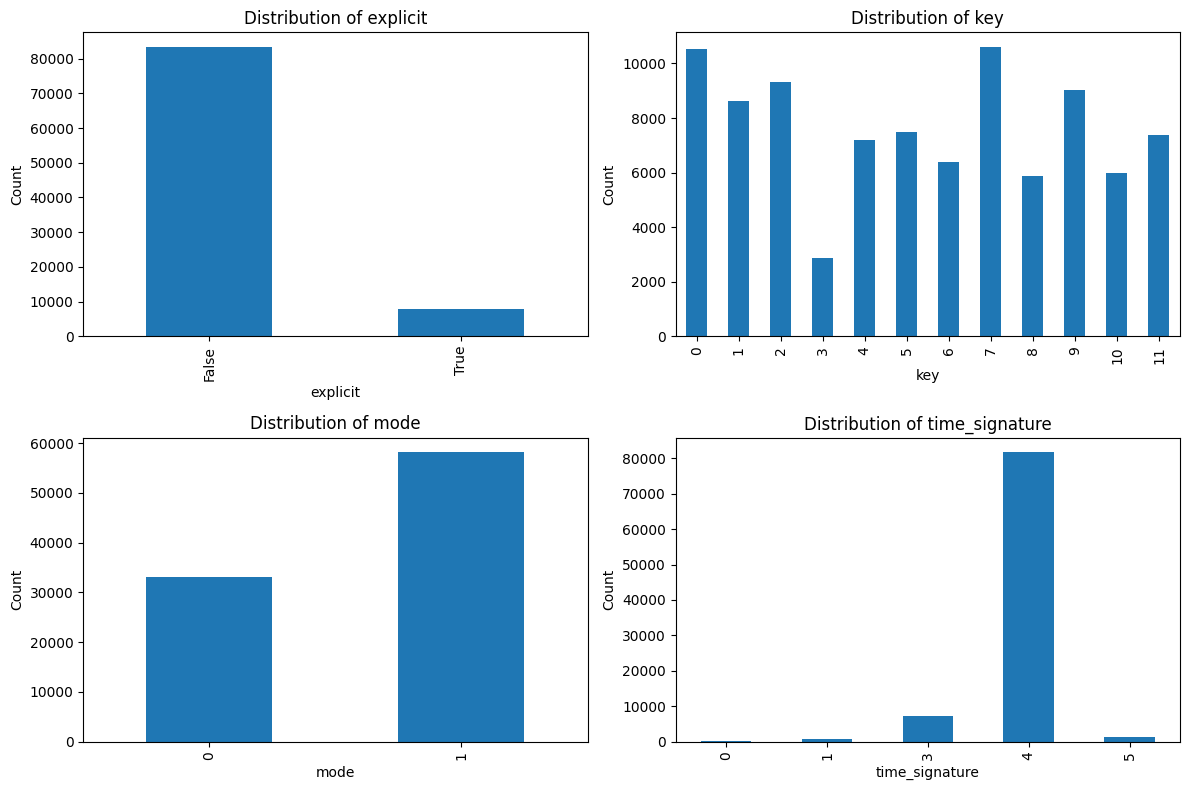

Text(0, 0.5, 'Genre')

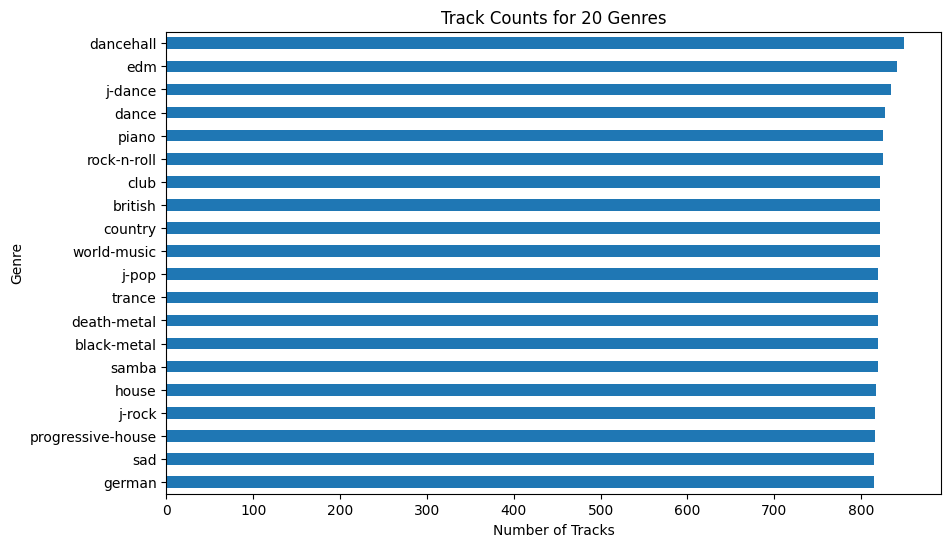

In [7]:
categorical_features = [
    "explicit",
    "key",
    "mode",
    "time_signature"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(categorical_features, axes.flatten()):
    training_df[feature].value_counts().sort_index().plot(
        kind="bar",
        ax=ax,
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

top_genres = training_df["TARGET"].value_counts().head(20)

plt.figure(figsize=(10, 6))

top_genres.sort_values().plot(kind="barh")

plt.title("Track Counts for 20 Genres")
plt.xlabel("Number of Tracks")
plt.ylabel("Genre")

### Categorical Feature Observations

The categorical attributes were examined to understand how different types of songs are represented in the dataset.

- Explicit: Most tracks are not marked as explicit. Only a relatively small portion of the      dataset contains explicit content.

- Key: Tracks occur in all 12 musical keys, although some keys appear more often than others.

- Mode: More tracks use major mode than minor mode.

- Time Signature: Most tracks use a 4/4 time signature. Other time signatures, such as 3/4 and 5/4, occur much less.

- Track Genre: The datset containes 114 genres. Each genre contains sbout 1,000 tracks.

### Distributions

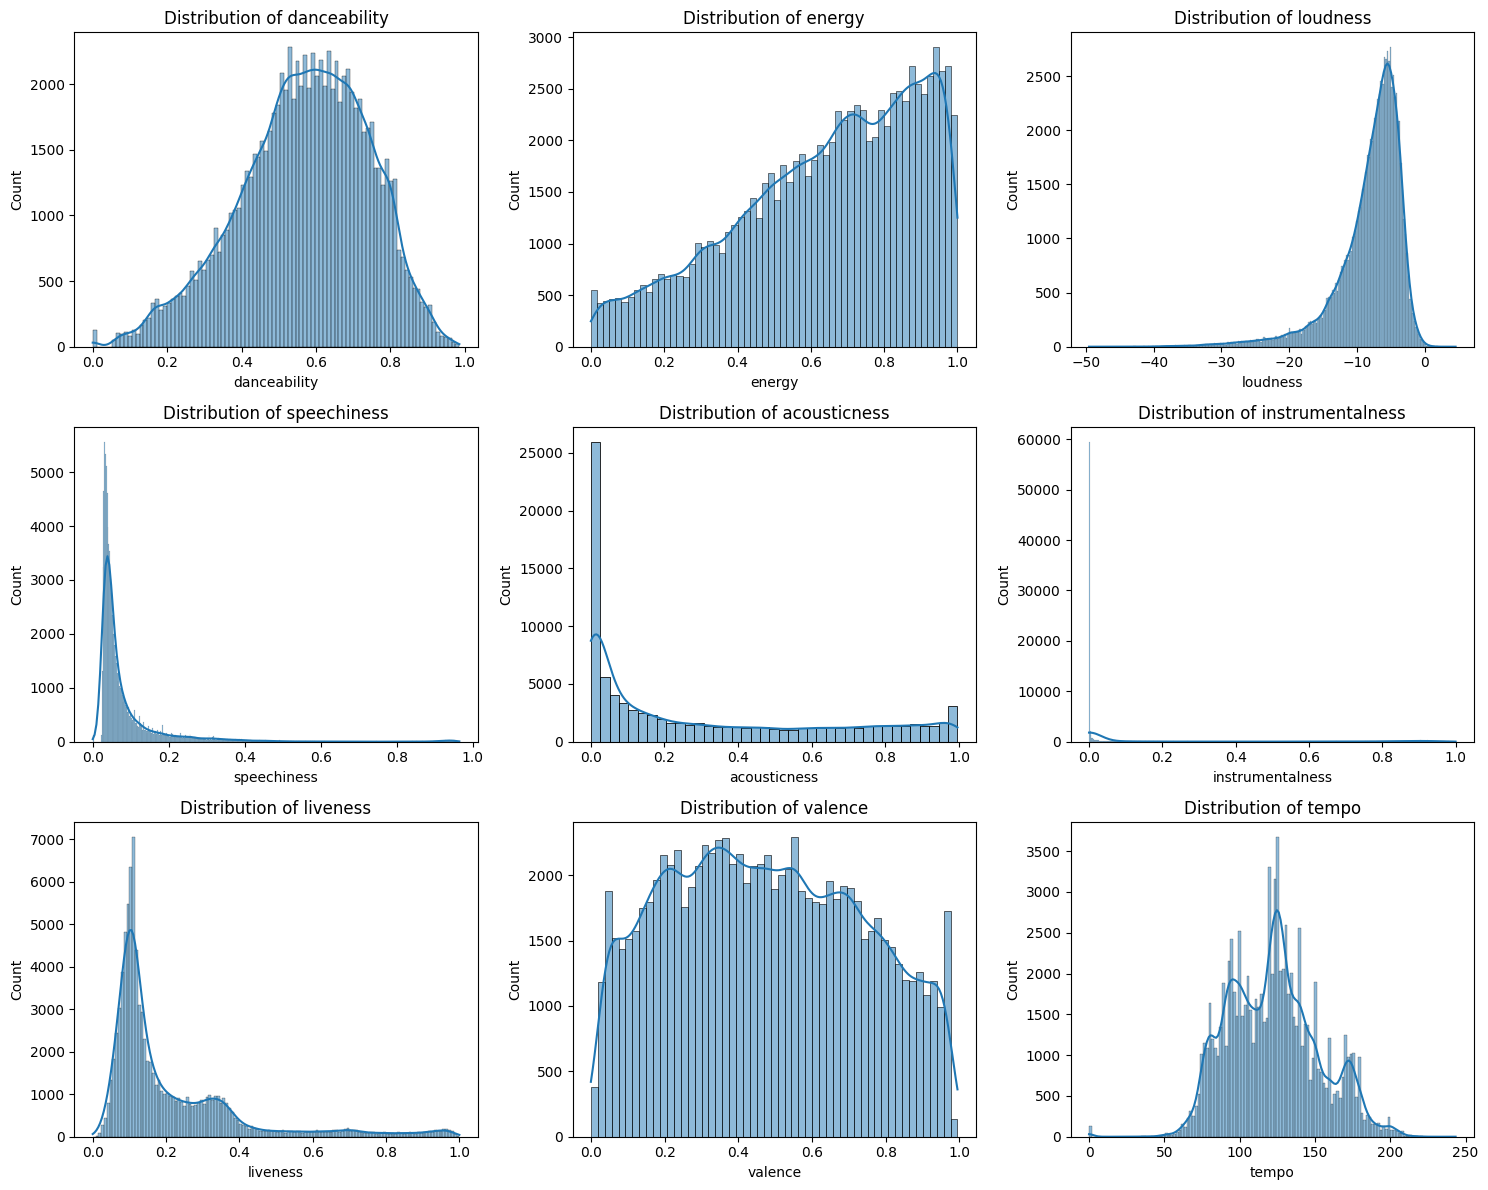

In [8]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for feature, ax in zip(audio_features, axes.flatten()):
    sns.histplot(
        data=training_df,
        x=feature,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

### Box-Whisker Plots

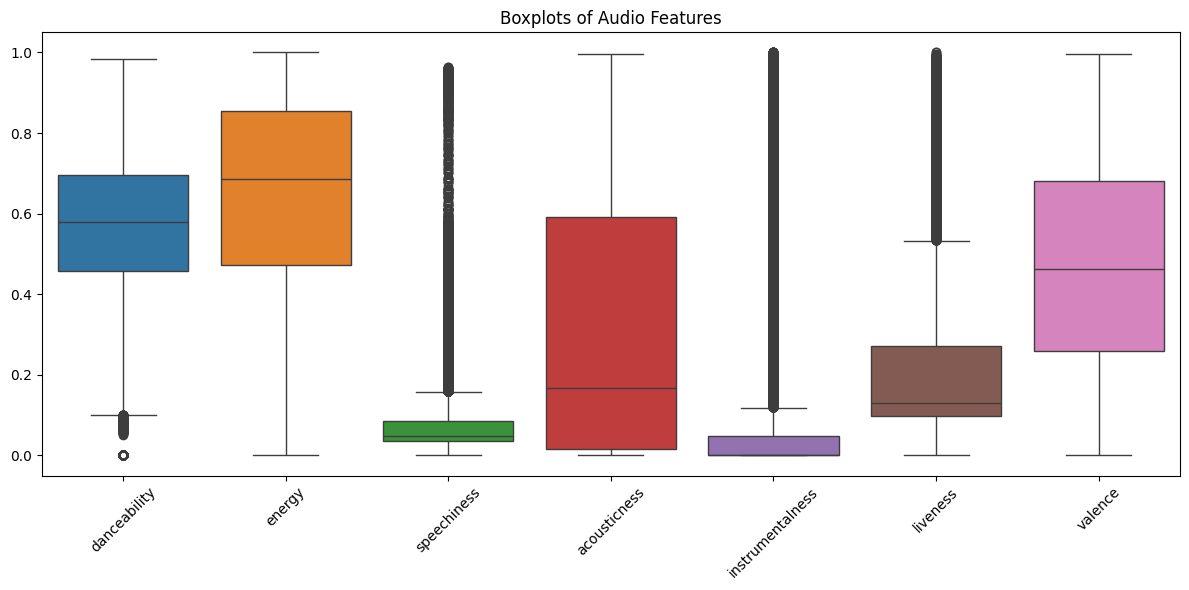

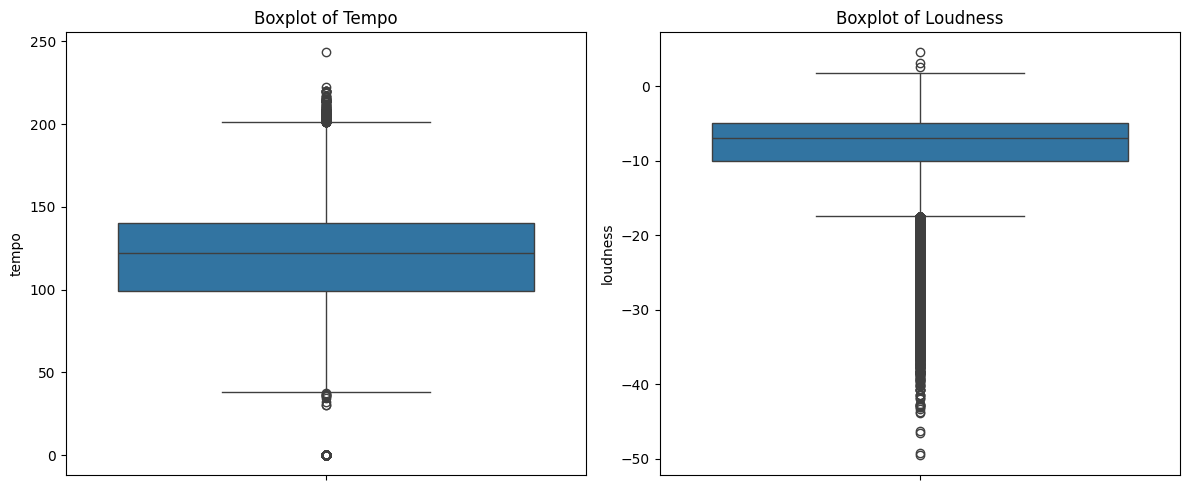

In [9]:
bounded_features = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence"
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=training_df[bounded_features])

plt.title("Boxplots of Audio Features")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=training_df["tempo"], ax=axes[0])
axes[0].set_title("Boxplot of Tempo")

sns.boxplot(y=training_df["loudness"], ax=axes[1])
axes[1].set_title("Boxplot of Loudness")

plt.tight_layout()
plt.show()

### Violin Plots

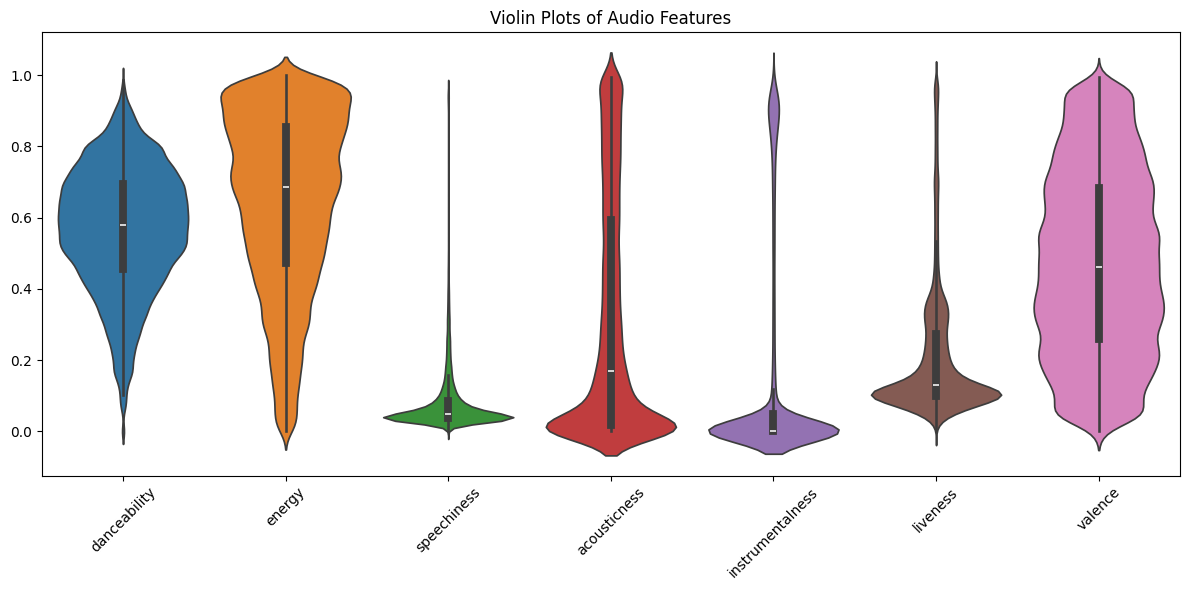

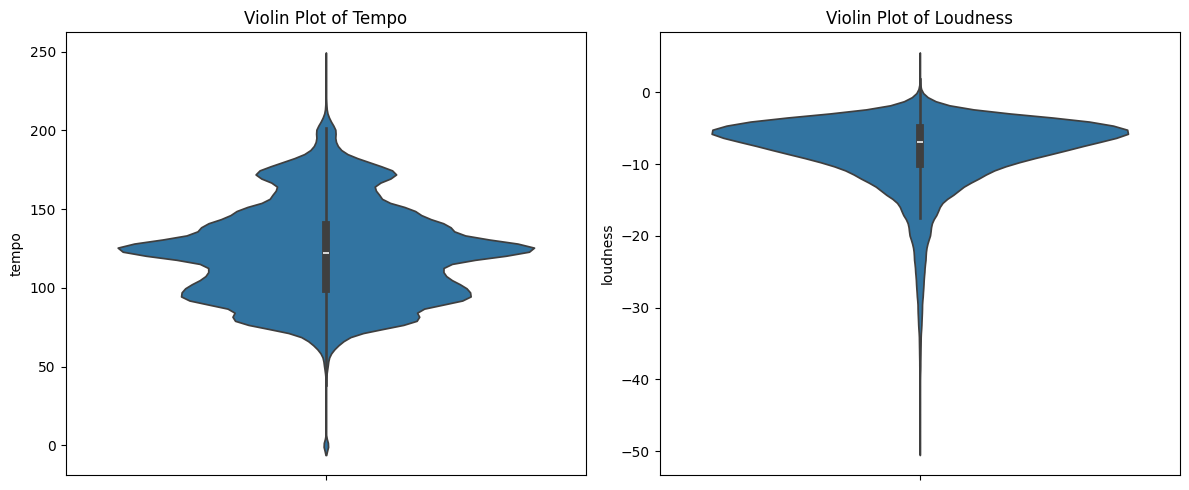

In [10]:
bounded_features = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence"
]

plt.figure(figsize=(12, 6))

sns.violinplot(data=training_df[bounded_features])

plt.title("Violin Plots of Audio Features")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.violinplot(y=training_df["tempo"], ax=axes[0])
axes[0].set_title("Violin Plot of Tempo")

sns.violinplot(y=training_df["loudness"], ax=axes[1])
axes[1].set_title("Violin Plot of Loudness")

plt.tight_layout()
plt.show()

## Data Quality & Cleaning

Instruction: Add a comment for each method

In [11]:
# Columns to check for outliers. Skipping speechiness, instrumentalness and liveliness because most songs are close to 0 or 1.
outlier_features = ["duration_ms", "loudness", "tempo"]

# finding first and third quartiles and the iqr for each feature
first_quartile = training_df[outlier_features].quantile(0.25)
third_quartile = training_df[outlier_features].quantile(0.75)
iqr = third_quartile - first_quartile

# catching outliers, anything > 1.5 iqr's below the first quartile or above the third quartile
lower_bound = first_quartile - 1.5 * iqr
upper_bound = third_quartile + 1.5 * iqr

# count each kind of data quality problem in the dataset
def count_quality_issues(frame):
    return pd.Series({
        # rows where there is one or more empty values
        "Rows with missing values": frame.isna().any(axis=1).sum(),
        # rows that are exact duplicates of other rows
        "Duplicate rows": frame.drop(columns="SAMPLE ID").duplicated().sum(),
        # duplicate song id
        "Repeated track_id": frame["track_id"].duplicated().sum(),
        # same artist and song title, differing id
        "Repeated artist + track title": frame.duplicated(subset=["artists", "track_name"]).sum(),
        # tempo of 0, means Spotify couldn't detect a beat implying the trakc is not a song
        "tempo = 0": (frame["tempo"] == 0).sum(),
        # dataset says time signature should be between 3 and 7
        "Invalid time signature": ((frame["time_signature"] < 3) | (frame["time_signature"] > 7)).sum(),
        # song with duration of 0
        "duration_ms = 0": (frame["duration_ms"] == 0).sum(),
        # loudness is generally negative, above 0db is not normal
        "loudness above 0 dB": (frame["loudness"] > 0).sum(),
        # dataset says speechincess above .66 is nearly all talking, not music
        "speechiness above 0.66": (frame["speechiness"] > 0.66).sum(),
    })

# count outliers for each feature
def count_outliers(frame):
    return ((frame[outlier_features] < lower_bound)| (frame[outlier_features] > upper_bound)).sum()

quality_report = pd.DataFrame({
    "Training": count_quality_issues(training_df),
    "Testing": count_quality_issues(testing_df)
})

outlier_report = pd.DataFrame({
    "Training": count_outliers(training_df),
    "Testing": count_outliers(testing_df)
})

display(quality_report)
display(outlier_report)

    



,Training,Testing
Rows with missing values,38,12
Duplicate rows,354,96
Repeated track_id,19520,4739
Repeated artist + track title,26209,6448
tempo = 0,131,26
Invalid time signature,894,242
duration_ms = 0,1,0
loudness above 0 dB,63,27
speechiness above 0.66,677,203


,Training,Testing
duration_ms,4589,1115
loudness,4937,1284
tempo,480,138


In [12]:

# Create copies of the original datasets for cleaning
clean_training_df = training_df.copy()
clean_testing_df = testing_df.copy()

# Check the initial dataset sizes
print("Training:", clean_training_df.shape)
print("Testing:", clean_testing_df.shape)


Training: (91283, 21)
Testing: (22717, 21)


In [13]:

# Handle missing values in text columns by replacing them with "Unknown"
text_columns = ["artists", "album_name", "track_name"]

clean_training_df[text_columns] = clean_training_df[text_columns].fillna("Unknown")
clean_testing_df[text_columns] = clean_testing_df[text_columns].fillna("Unknown")

# Verify that no missing values remain
print("Missing values in Training:", clean_training_df.isna().sum().sum())
print("Missing values in Testing:", clean_testing_df.isna().sum().sum())


Missing values in Training: 0
Missing values in Testing: 0


In [14]:

# Remove exact duplicate records, excluding the unique SAMPLE ID
duplicate_columns = clean_training_df.columns.drop("SAMPLE ID")

clean_training_df = clean_training_df.drop_duplicates(
    subset=duplicate_columns
).copy()

clean_testing_df = clean_testing_df.drop_duplicates(
    subset=duplicate_columns
).copy()

# Verify that duplicate records have been removed
print("Training duplicates:", clean_training_df.duplicated(subset=duplicate_columns).sum())
print("Testing duplicates:", clean_testing_df.duplicated(subset=duplicate_columns).sum())

# Check the remaining dataset sizes
print("Training shape:", clean_training_df.shape)
print("Testing shape:", clean_testing_df.shape)


Training duplicates: 0
Testing duplicates: 0
Training shape: (90929, 21)
Testing shape: (22621, 21)


In [15]:

# Replace zero values in duration and tempo with the training median
# to avoid losing songs with otherwise valid audio features.

columns_to_fix = ["duration_ms", "tempo"]

for column in columns_to_fix:
    replacement = clean_training_df.loc[
        clean_training_df[column] > 0, column
    ].median()

    clean_training_df.loc[
        clean_training_df[column] == 0, column
    ] = replacement

    clean_testing_df.loc[
        clean_testing_df[column] == 0, column
    ] = replacement

# Verify that zero values have been corrected
print("Training zero durations:", (clean_training_df["duration_ms"] == 0).sum())
print("Testing zero durations:", (clean_testing_df["duration_ms"] == 0).sum())
print("Training zero tempos:", (clean_training_df["tempo"] == 0).sum())
print("Testing zero tempos:", (clean_testing_df["tempo"] == 0).sum())


Training zero durations: 0
Testing zero durations: 0
Training zero tempos: 0
Testing zero tempos: 0


In [16]:

# Replace invalid time signatures (0) with the most frequent
# valid value from Training, using the same value for Testing.

valid_time_signatures = clean_training_df.loc[
    clean_training_df["time_signature"] > 0, "time_signature"
]

replacement_time_signature = valid_time_signatures.mode().iloc[0]

clean_training_df.loc[
    clean_training_df["time_signature"] == 0, "time_signature"
] = replacement_time_signature

clean_testing_df.loc[
    clean_testing_df["time_signature"] == 0, "time_signature"
] = replacement_time_signature

# Verify the results
print("Replacement value:", replacement_time_signature)
print("Training invalid time signatures:",
      (clean_training_df["time_signature"] == 0).sum())
print("Testing invalid time signatures:",
      (clean_testing_df["time_signature"] == 0).sum())


Replacement value: 4
Training invalid time signatures: 0
Testing invalid time signatures: 0


In [17]:

# Check whether numeric features are within their expected ranges.
# Values outside these ranges may indicate data quality issues.

valid_ranges = {
    "popularity": (0, 100),
    "danceability": (0, 1),
    "energy": (0, 1),
    "key": (0, 11),
    "mode": (0, 1),
    "speechiness": (0, 1),
    "acousticness": (0, 1),
    "instrumentalness": (0, 1),
    "liveness": (0, 1),
    "valence": (0, 1)
}

for dataset_name, dataset in [
    ("Training", clean_training_df),
    ("Testing", clean_testing_df)
]:
    print(f"\n{dataset_name} invalid values:")
    for column, (minimum, maximum) in valid_ranges.items():
        invalid_count = (~dataset[column].between(minimum, maximum)).sum()
        print(f"{column}: {invalid_count}")



Training invalid values:
popularity: 0
danceability: 0
energy: 0
key: 0
mode: 0
speechiness: 0
acousticness: 0
instrumentalness: 0
liveness: 0
valence: 0

Testing invalid values:
popularity: 0
danceability: 0
energy: 0
key: 0
mode: 0
speechiness: 0
acousticness: 0
instrumentalness: 0
liveness: 0
valence: 0


In [18]:

# Identify potential outliers using the IQR method.
# Outliers are reviewed before deciding whether to modify them.

outlier_columns = ["duration_ms", "loudness", "tempo"]

for column in outlier_columns:
    Q1 = clean_training_df[column].quantile(0.25)
    Q3 = clean_training_df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"\n{column}:")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")

    for name, dataset in [
        ("Training", clean_training_df),
        ("Testing", clean_testing_df)
    ]:
        outliers = (
            (dataset[column] < lower_bound) |
            (dataset[column] > upper_bound)
        ).sum()

        print(f"{name} outliers: {outliers}")



duration_ms:
Lower bound: 44230.00
Upper bound: 391766.00
Training outliers: 4569
Testing outliers: 1112

loudness:
Lower bound: -17.46
Upper bound: 2.47
Training outliers: 4880
Testing outliers: 1263

tempo:
Lower bound: 38.92
Upper bound: 200.75
Training outliers: 367
Testing outliers: 113



### Outlier Treatment

The IQR method was used to detect potential outliers in duration_ms, loudness, and tempo.

Outliers were retained because extreme values may represent valid songs. Removing them could cause unnecessary data loss and affect clustering results.


In [19]:

# Final verification of data cleaning results
# Compare original and cleaned datasets.

for name, original, cleaned in [
    ("Training", training_df, clean_training_df),
    ("Testing", testing_df, clean_testing_df)
]:
    print(f"\n{name} - Final Cleaning Summary")
    print("Original shape:", original.shape)
    print("Cleaned shape:", cleaned.shape)
    print("Original missing values:", original.isna().sum().sum())
    print("Remaining missing values:", cleaned.isna().sum().sum())
    print("Remaining duplicates:",
          cleaned.drop(columns="SAMPLE ID").duplicated().sum())
    print("Zero durations:", (cleaned["duration_ms"] == 0).sum())
    print("Zero tempos:", (cleaned["tempo"] == 0).sum())
    print("Invalid time signatures:",
          (cleaned["time_signature"] == 0).sum())



Training - Final Cleaning Summary
Original shape: (91283, 21)
Cleaned shape: (90929, 21)
Original missing values: 49
Remaining missing values: 0
Remaining duplicates: 0
Zero durations: 0
Zero tempos: 0
Invalid time signatures: 0

Testing - Final Cleaning Summary
Original shape: (22717, 21)
Cleaned shape: (22621, 21)
Original missing values: 12
Remaining missing values: 0
Remaining duplicates: 0
Zero durations: 0
Zero tempos: 0
Invalid time signatures: 0


### Before and After Cleaning Examples

The following examples show how selected data quality issues changed after cleaning.


In [20]:
# Find a few rows that had missing text values before cleaning
missing_examples = training_df[
    training_df[["artists", "album_name", "track_name"]].isna().any(axis=1)
].head(5)

missing_examples[["artists", "album_name", "track_name"]]

,artists,album_name,track_name
48994,NaN,探せ ダイヤモンドリリー,いらない ツインテール
48998,NaN,CAMEO,「君と私の歌」
48999,NaN,NaN,NaN
49000,NaN,あの子コンプレックス,知らんけど
49001,NaN,全部、内緒。 (Special Edition),NaN


In [21]:
# Show same rows after cleaning
clean_training_df.loc[
    missing_examples.index, ["artists", "album_name", "track_name"]
]

,artists,album_name,track_name
48994,Unknown,探せ ダイヤモンドリリー,いらない ツインテール
48998,Unknown,CAMEO,「君と私の歌」
48999,Unknown,Unknown,Unknown
49000,Unknown,あの子コンプレックス,知らんけど
49001,Unknown,全部、内緒。 (Special Edition),Unknown


In [22]:
# Find a few tracks that had tempo equal to 0 before cleaning
tempo_examples = training_df[
    training_df["tempo"] == 0
].head(5)

tempo_examples[["track_name", "tempo"]]

,track_name,tempo
3316,The Departure,0.0
3520,The End of Childhood (feat. Jack Liebeck),0.0
3757,Ferme Les Yeux,0.0
36721,Campomoro,0.0
36758,Ritornello,0.0


In [23]:
# Show the same rows after cleaning
clean_training_df.loc[
    tempo_examples.index,
    ["track_name", "tempo"]
]

,track_name,tempo
3316,The Departure,122.02
3520,The End of Childhood (feat. Jack Liebeck),122.02
3757,Ferme Les Yeux,122.02
36721,Campomoro,122.02
36758,Ritornello,122.02


In [24]:
# Find tracks with an invalid time signature before cleaning
time_signature_examples = training_df[
    training_df["time_signature"] == 0
].head(5)

time_signature_examples[["track_name", "time_signature"]]

,track_name,time_signature
2352,Sanki Yapamadım,0
3316,The Departure,0
3520,The End of Childhood (feat. Jack Liebeck),0
3757,Ferme Les Yeux,0
36721,Campomoro,0


In [25]:
# Shows same rows after cleaning
clean_training_df.loc[
    time_signature_examples.index,
    ["track_name", "time_signature"]
]

,track_name,time_signature
2352,Sanki Yapamadım,4
3316,The Departure,4
3520,The End of Childhood (feat. Jack Liebeck),4
3757,Ferme Les Yeux,4
36721,Campomoro,4


In [26]:
# Find tracks with duration equal to 0 before cleaning
duration_examples = training_df[
    training_df["duration_ms"] == 0
]

duration_examples[["track_name", "duration_ms"]]

,track_name,duration_ms
52903,NaN,0


In [27]:
# Show same rows after cleaning
clean_training_df.loc[
    duration_examples.index,
    ["track_name", "duration_ms"]
]

,track_name,duration_ms
52903,Unknown,213000


## Handling Redundancy

### X-square Test

In [28]:
from scipy.stats import chi2_contingency

# Contingency table: musical key vs. major/minor mode
contingency_table = pd.crosstab(
    clean_training_df["key"],
    clean_training_df["mode"]
)

display(contingency_table)

# Chi-square test of independence
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Cramer's V measures the strength of the association
n = contingency_table.to_numpy().sum()
cramers_v = (
    chi2 / (n * min(contingency_table.shape[0] - 1,
                   contingency_table.shape[1] - 1))
) ** 0.5

print(f"Chi-square: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4e}")
print(f"Cramer's V: {cramers_v:.4f}")
print(f"Minimum expected count: {expected.min():.2f}")

mode,0,1
key,,
0,2310,8191
1,2827,5757
2,2058,7223
3,1029,1830
4,3752,3428
5,3209,4229
6,3068,3287
7,2392,8185
8,1556,4310


Chi-square: 6037.6956
Degrees of freedom: 11
P-value: 0.0000e+00
Cramer's V: 0.2577
Minimum expected count: 1035.55


**Chi-Square conclusion**:
We tested whether musical key and mode are independent. The test gives χ² = 6037.7 with 11 degrees of freedom and p ≈ 0, so key and mode are not independent. Some keys (4 and 11) lean minor while others (0, 2, and 7) lean major.

With about 91,000 songs, a very small association wil be statistically significant, so the p-value alone doesn't tell us how strong the relationship is. Cramer's V = 0.26, which is a weak-to-moderate association. Knowing a song's key does not reliably tell us its mode, so neither attribute is redundant with the other. The smallest expected count is about 1,036, well above 5, so the test's assumptions are met.

### Correlation Analysis

In [29]:
# Numerical features for correlation analysis
numeric_features = [
    "popularity", "duration_ms", "danceability", "energy",
    "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo"
]

# Pearson correlation matrix
correlation_matrix = clean_training_df[numeric_features].corr()

display(correlation_matrix.round(3))

,popularity,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
popularity,1.000,-0.010,0.033,-0.006,0.043,-0.046,-0.020,-0.095,-0.006,-0.035,0.012
duration_ms,-0.010,1.000,-0.074,0.056,-0.006,-0.061,-0.100,0.125,0.011,-0.152,0.024
danceability,0.033,-0.074,1.000,0.127,0.253,0.108,-0.168,-0.183,-0.135,0.474,-0.071
energy,-0.006,0.056,0.127,1.000,0.760,0.143,-0.731,-0.178,0.183,0.254,0.236
loudness,0.043,-0.006,0.253,0.760,1.000,0.062,-0.587,-0.431,0.075,0.276,0.198
speechiness,-0.046,-0.061,0.108,0.143,0.062,1.000,-0.005,-0.090,0.197,0.040,0.016
acousticness,-0.020,-0.100,-0.168,-0.731,-0.587,-0.005,1.000,0.101,-0.019,-0.100,-0.202
instrumentalness,-0.095,0.125,-0.183,-0.178,-0.431,-0.090,0.101,1.000,-0.079,-0.323,-0.043
liveness,-0.006,0.011,-0.135,0.183,0.075,0.197,-0.019,-0.079,1.000,0.019,0.007
valence,-0.035,-0.152,0.474,0.254,0.276,0.040,-0.100,-0.323,0.019,1.000,0.068


**Correlation Conclusion**:
We used Pearson correlation to chack for redundancy between numeric features, treating |r| >= 0.75 as redundant.

- **Strong**: energy and loudness (r = 0.76), energy and acousticness (r = -0.73)
- **Moderate**: loudness and acousticness (r = -0.59), danceability and valence (r = 0.47), loudness and instrumentalness (r = -0.43)
- **Weak**: all other pairs (|r| < 0.33); popularity has almost no correlation with any audio feature

Only energy and loudness are above out threshold. Energy and acousticness are close (r = -0.73), so we looked at the scatter plot before deciding about acousticness.

### Visual Exploration (scatter-plot matrix)

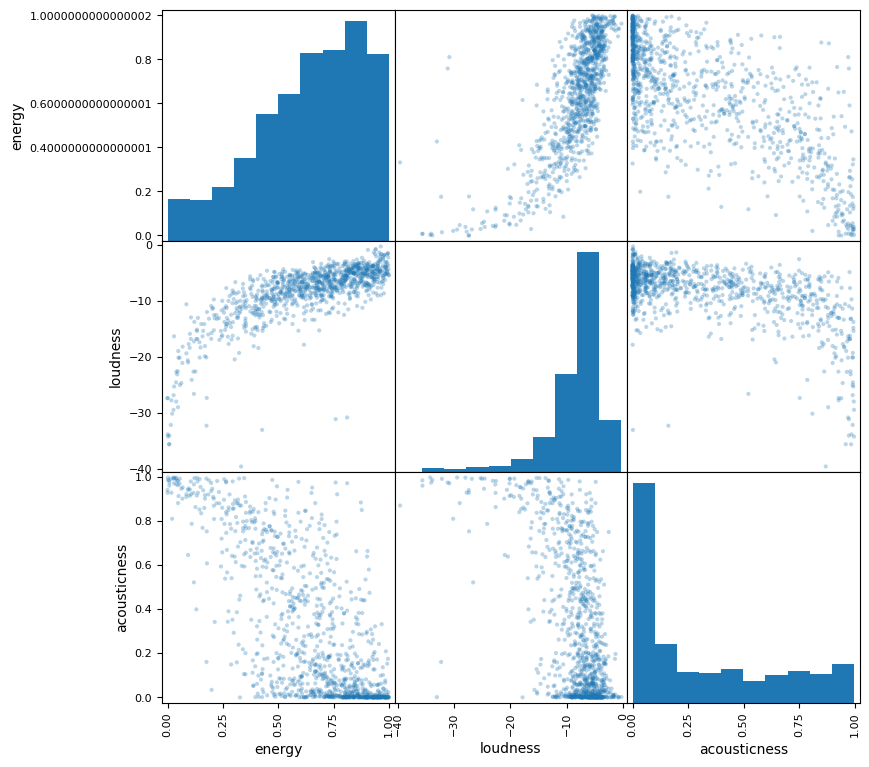

In [30]:
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt

# Reproducible sample to keep the plot readable
sample = clean_training_df[
    ["energy", "loudness", "acousticness"]
].sample(n=1000, random_state=42)

scatter_matrix(
    sample,
    figsize=(9, 9),
    alpha=0.3,
    diagonal="hist"
)

plt.show()

**Scatter-plot conclusion**:
The scatter-plot matric (1,000 randomly sampled songs) shows the relationship between energy, loudness, and acousticness.

- **Energy vs loudness**: a tight, curved relationship. Loudness increases quickly at low energy levels off around -5 dB. Pearson's r only measures straight-line relationships, so r = 0.76 actually understates how closely these two are linked. This confirms they are redundant.
- **Energy vs acousticness**: a negative trend, but with a lot of spred. Many songs have acousticness near 0 at every energy level, so acousticness still carries information that energy doesn't.
- **Loudness vs acousticness**: a loose, fan-shaped spread, so a weak relationship.

### Feature Selection Summary

- **Loudness**: Exclude, redundant with energy (r = 0.76, and nonlinear)
- **Energy**: Keep, Kept over loudness since since it related to both loudness and acousticness
- **Acousticness**: Keep, below the threshold, and the scatter plot shows it added information
- **Key, Mode**: Exclude, not redundant (Cramer's V = 0.26), but they are category codes, so distances between them are meaningless for K-means
- **Danceability, Valence, Speechiness, Instrumentalness, Liveness, Tempo**: Keep, no redundancy with other features
- **Popularity, Duration_ms, Explicit, Time_signature**: Exclude, doesn't contribute to the goal of the project

## Dimensionality Reduction

### PCA

In [35]:
# Features selected after the redundancy analysis
selected_features = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

X_train = clean_training_df[selected_features]
X_test = clean_testing_df[selected_features]

X_train.head()

,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.676,0.4610,0.1430,0.0322,0.000001,0.3580,0.715,87.917
1,0.420,0.1660,0.0763,0.9240,0.000006,0.1010,0.267,77.489
2,0.438,0.3590,0.0557,0.2100,0.000000,0.1170,0.120,76.332
3,0.266,0.0596,0.0363,0.9050,0.000071,0.1320,0.143,181.740
4,0.618,0.4430,0.0526,0.4690,0.000000,0.0829,0.167,119.949


In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)


(90929, 8)
(22621, 8)


In [37]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

for i in range(len(explained_variance)):
    print(
        f"PC{i + 1}: "
        f"{explained_variance[i]:.3f} "
        f"(Cumulative: {cumulative_variance[i]:.3f})"
    )

PC1: 0.272 (Cumulative: 0.272)
PC2: 0.179 (Cumulative: 0.451)
PC3: 0.151 (Cumulative: 0.601)
PC4: 0.115 (Cumulative: 0.716)
PC5: 0.107 (Cumulative: 0.824)
PC6: 0.091 (Cumulative: 0.914)
PC7: 0.059 (Cumulative: 0.973)
PC8: 0.027 (Cumulative: 1.000)


In [38]:
# Reduce the data to 6 principal components
pca_final = PCA(n_components=6)

X_train_pca = pca_final.fit_transform(X_train_scaled)
X_test_pca = pca_final.transform(X_test_scaled)

print("Training PCA shape:", X_train_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)
print("Total variance retained:", pca_final.explained_variance_ratio_.sum())

Training PCA shape: (90929, 6)
Testing PCA shape: (22621, 6)
Total variance retained: 0.9144866040690819


### PCA Conclusion

PCA reduced the 8 selected features to 6 principal components while keeping about 91.4% of the total variance. This gives us a smaller representation of the data while keeping most of the original information.

## Discretization

In [39]:
from sklearn.preprocessing import KBinsDiscretizer

# split each feature into 3 groups: low, medium, and high.
discretizer = KBinsDiscretizer(
    n_bins=3,
    encode="ordinal",
    strategy="quantile"
)

X_train_discretized = discretizer.fit_transform(X_train)
X_test_discretized = discretizer.transform(X_test)

# Convert back into DataFrame for viewing
train_discretized_df = pd.DataFrame(
    X_train_discretized,
    columns=selected_features,
    index=X_train.index
).astype(int)

test_discretized_df = pd.DataFrame(
    X_test_discretized,
    columns=selected_features,
    index=X_test.index
).astype(int)

train_discretized_df.head()

c:\Users\hunte\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\hunte\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(


,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,2,0,2,0,0,2,2,0
1,0,0,2,2,0,0,0,0
2,0,0,1,1,0,1,0,0
3,0,0,0,2,0,1,0,2
4,1,0,1,2,0,0,0,1


In [43]:
train_discretized_df.nunique()

danceability        3
energy              3
speechiness         3
acousticness        3
instrumentalness    2
liveness            3
valence             3
tempo               3
dtype: int64

### Discretization Note

Most features were divided into three groups: Low, Medium, and High. Instrumentalness only produced two groups because many songs have the same or very similar instrumentalness values near 0.

### Histogram of Discretized Attribute

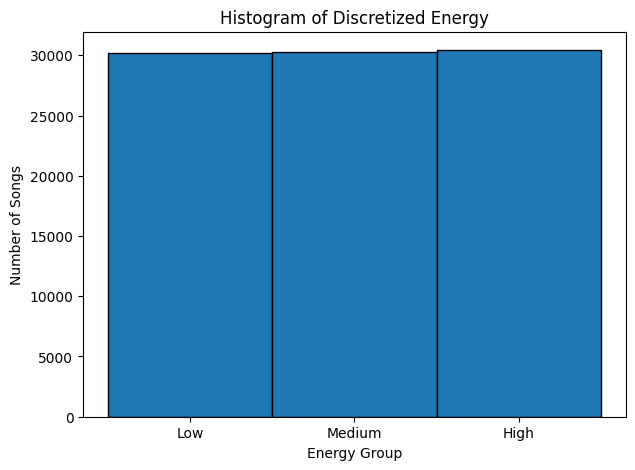

In [40]:
# Histogram of discretized energy values
plt.figure(figsize=(7, 5))

plt.hist(
    train_discretized_df["energy"],
    bins=[-0.5, 0.5, 1.5, 2.5],
    edgecolor="black"
)

plt.xticks([0, 1, 2], ["Low", "Medium", "High"])
plt.xlabel("Energy Group")
plt.ylabel("Number of Songs")
plt.title("Histogram of Discretized Energy")

plt.show()

The energy values were divided into three groups: Low, Medium, and High. The groups contain roughly the same number of songs because quantile based discretization was used.

### X-square Test of Discretized Attributes

In [41]:
from scipy.stats import chi2_contingency

# Compare discretized energy and acousticness
contingency_table = pd.crosstab(
    train_discretized_df["energy"],
    train_discretized_df["acousticness"]
)

display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square:", round(chi2, 2))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

acousticness,0,1,2
energy,,,
0,1872,6762,21575
1,8964,14754,6569
2,19440,8808,2185


Chi-square: 39355.33
Degrees of freedom: 4
P-value: 0.0


### Chi-Square Conclusion

The chi-square test showed a very small p-value, so discretized energy and acousticness are related. Low energy songs were more likely to have high acousticness, while high energy songs were more likely to have low acousticness.

### Visual Exploration (scatter-plot matrix) of Discretized Attributes

array([[<Axes: xlabel='energy', ylabel='energy'>,
        <Axes: xlabel='acousticness', ylabel='energy'>,
        <Axes: xlabel='danceability', ylabel='energy'>,
        <Axes: xlabel='valence', ylabel='energy'>],
       [<Axes: xlabel='energy', ylabel='acousticness'>,
        <Axes: xlabel='acousticness', ylabel='acousticness'>,
        <Axes: xlabel='danceability', ylabel='acousticness'>,
        <Axes: xlabel='valence', ylabel='acousticness'>],
       [<Axes: xlabel='energy', ylabel='danceability'>,
        <Axes: xlabel='acousticness', ylabel='danceability'>,
        <Axes: xlabel='danceability', ylabel='danceability'>,
        <Axes: xlabel='valence', ylabel='danceability'>],
       [<Axes: xlabel='energy', ylabel='valence'>,
        <Axes: xlabel='acousticness', ylabel='valence'>,
        <Axes: xlabel='danceability', ylabel='valence'>,
        <Axes: xlabel='valence', ylabel='valence'>]], dtype=object)

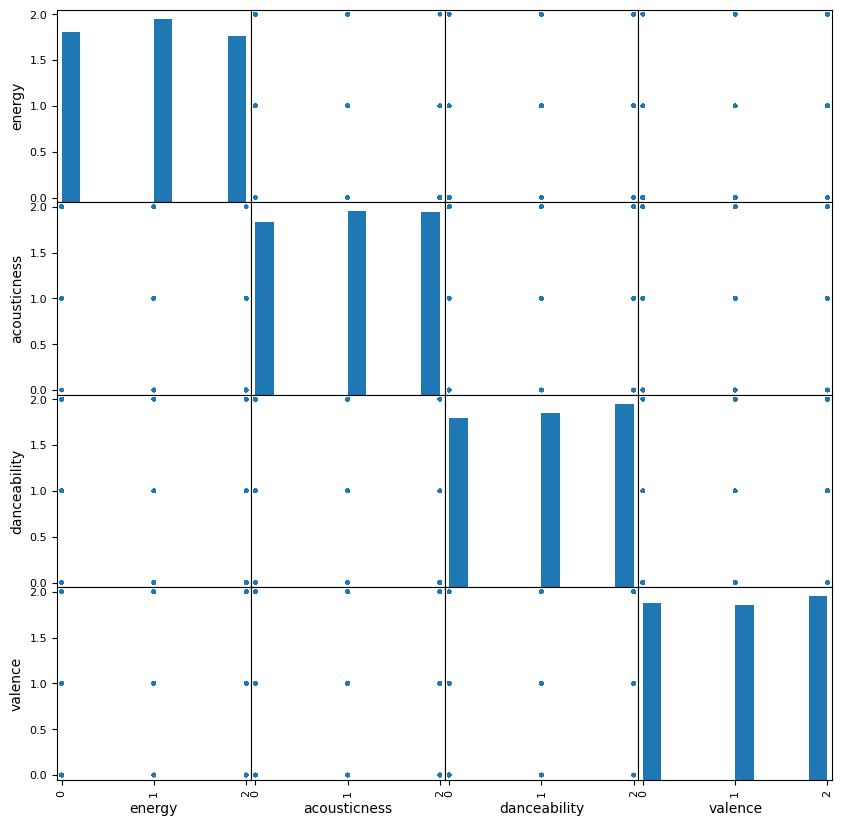

In [42]:
from pandas.plotting import scatter_matrix

# Use a sample so the graph is readable
discretized_sample = train_discretized_df[
    ["energy", "acousticness", "danceability", "valence"]
].sample(n=1000, random_state=42)

scatter_matrix(
    discretized_sample,
    figsize=(10, 10),
    alpha=0.3,
    diagonal="hist"
)

### Scatter Plot Conclusion

The scatter plots show the relationships between the discretized features. Since each feature was divided into Low, Medium, and High groups, the points are grouped at values 0, 1, and 2 instead of being spread continuously.

Energy and acousticness still show an opposite relationship, while the other features show more variation between groups.

## Feature Selection/Generation

### Select Features

### Generate Features

# Generate Clusters

## K-means

## Hierarchical

# Evaluation of Clusters

See instructions provided in the report template

## <center> REFERENCES </center>
List resources (book, internet page, etc.) that you used to complete this challenge.